In [ ]:

# Imports & Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style("whitegrid")
np.random.seed(42)
print("Imports OK")

Imports OK


In [3]:
#Load & Inspect
retail = pd.read_csv('Retail_stores.csv')
print("Shape:", retail.shape)
print("\nColumns:", retail.columns.tolist())
print("\nData types:\n", retail.dtypes)
retail.head()

Shape: (5100, 14)

Columns: ['StoreID', 'Region', 'StoreType', 'MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours', 'DiscountRate', 'CustomerSatisfaction', 'InventoryAvailability', 'CompetitorDistance', 'PreviousMonthSales', 'Season', 'SalesRevenue']

Data types:
 StoreID                    int64
Region                       str
StoreType                    str
MarketingSpend           float64
Footfall                 float64
OnlineTraffic            float64
StaffHours               float64
DiscountRate             float64
CustomerSatisfaction     float64
InventoryAvailability    float64
CompetitorDistance       float64
PreviousMonthSales       float64
Season                       str
SalesRevenue             float64
dtype: object


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1051,North,Mall,3112.970133,1194.757278,5995.253123,295.914621,19.067494,NaN,81.001043,12.969511,50135.817486,Summer,249522.51
1,1092,North,Town,6318.707486,1893.939723,9399.307313,303.880533,4.222433,59.670866,83.521835,17.890113,46881.417221,Winter,362564.72
2,1014,North,Retail Park,4934.112301,1280.261621,13337.943755,347.676004,4.259883,76.553271,95.342429,19.873263,50382.031910,Winter,315300.65
3,1071,North,Town,6631.180326,728.987814,6510.314785,337.097053,38.564438,85.944732,90.215647,11.560488,48063.975734,Winter,360506.70
4,1060,South,Town,5262.867791,602.074362,10394.071431,327.638120,39.174709,67.329625,76.199892,7.291224,44882.500605,Autumn,323011.58


=== MISSING VALUES ===
                       MissingCount  MissingPct
InventoryAvailability           358        7.02
OnlineTraffic                   355        6.96
MarketingSpend                  353        6.92
CustomerSatisfaction            352        6.90


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\319598595.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing.index, y=missing['MissingPct'], palette='Reds_r')


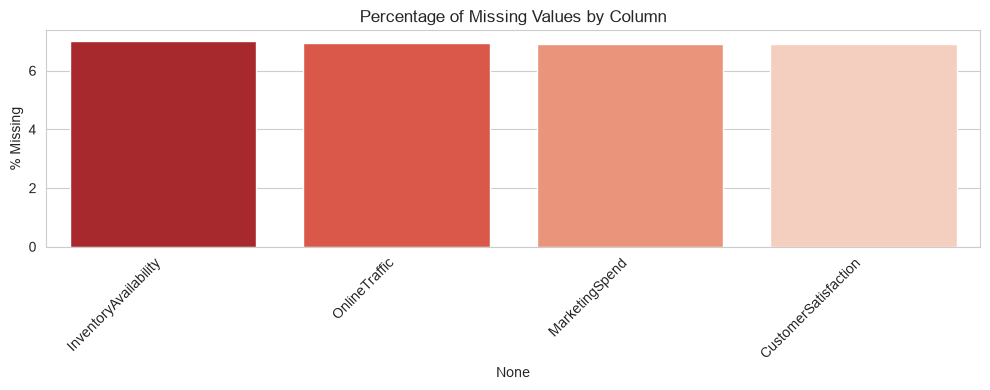

In [4]:
missing = pd.DataFrame({
    'MissingCount': retail.isnull().sum(),
    'MissingPct': (retail.isnull().sum() / len(retail) * 100).round(2)
})
missing = missing[missing['MissingCount'] > 0].sort_values('MissingPct', ascending=False)
print("=== MISSING VALUES ===")
print(missing)

if len(missing) > 0:
    plt.figure(figsize=(10, 4))
    sns.barplot(x=missing.index, y=missing['MissingPct'], palette='Reds_r')
    plt.title('Percentage of Missing Values by Column')
    plt.ylabel('% Missing')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [5]:
print("=== DUPLICATES ===")
print(f"Full duplicate rows: {retail.duplicated().sum()}")
print(f"Repeated StoreIDs:   {retail['StoreID'].duplicated().sum()}")
print(f"Unique StoreIDs:     {retail['StoreID'].nunique()}")

business_key = ['StoreID', 'Season', 'Region']
dup_business = retail.duplicated(subset=business_key).sum()
print(f"Duplicates on business key {business_key}: {dup_business}")

=== DUPLICATES ===
Full duplicate rows: 100
Repeated StoreIDs:   5000
Unique StoreIDs:     100
Duplicates on business key ['StoreID', 'Season', 'Region']: 3575


In [6]:
numeric_cols = [c for c in retail.select_dtypes(include=np.number).columns if c != 'StoreID']

outlier_summary = []
for col in numeric_cols:
    s = retail[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((s < lower) | (s > upper)).sum()
    outlier_summary.append({
        'Column': col, 'Q1': round(q1,2), 'Q3': round(q3,2),
        'Lower': round(lower,2), 'Upper': round(upper,2),
        'Outliers': n_out, 'OutlierPct': round(n_out/len(s)*100, 2)
    })

outliers = pd.DataFrame(outlier_summary).sort_values('OutlierPct', ascending=False)
print("=== OUTLIER SUMMARY (IQR) ===")
print(outliers.to_string(index=False))

=== OUTLIER SUMMARY (IQR) ===
               Column        Q1        Q3     Lower     Upper  Outliers  OutlierPct
       MarketingSpend   3976.51   6059.86    851.48   9184.88        71        1.50
         SalesRevenue 285897.32 348445.68 192074.78 442268.22        72        1.41
             Footfall    964.95   1444.26    245.99   2163.23        38        0.75
   PreviousMonthSales  38768.14  50937.01  20514.84  69190.31        30        0.59
        OnlineTraffic   6850.05  10247.97   1753.18  15344.85        26        0.55
           StaffHours    293.49    403.38    128.65    568.22        26        0.51
 CustomerSatisfaction     68.19     81.67     47.96    101.90        13        0.27
InventoryAvailability     79.48     90.54     62.90    107.13         9        0.19
         DiscountRate     10.06     29.90    -19.70     59.66         0        0.00
   CompetitorDistance      5.50     15.24     -9.11     29.85         0        0.00


In [7]:
retail_clean = retail.copy()
print("Missing BEFORE:", retail_clean.isnull().sum().sum())

# Median imputation for skewed numeric features
for col in ['MarketingSpend', 'CustomerSatisfaction', 'OnlineTraffic', 'InventoryAvailability']:
    if col in retail_clean.columns:
        med = retail_clean[col].median()
        retail_clean[col] = retail_clean[col].fillna(med)
        print(f"Filled {col} with median = {med:.2f}")

# Drop true duplicates only
before = len(retail_clean)
retail_clean = retail_clean.drop_duplicates(subset=['StoreID','Season','Region'], keep='first')
print(f"\nDuplicates removed: {before - len(retail_clean)}")

# Winsorise MarketingSpend at 99th percentile
cap_99 = retail_clean['MarketingSpend'].quantile(0.99)
n_capped = (retail_clean['MarketingSpend'] > cap_99).sum()
retail_clean['MarketingSpend'] = retail_clean['MarketingSpend'].clip(upper=cap_99)
print(f"MarketingSpend capped at {cap_99:.2f}; records affected: {n_capped}")

print("\nMissing AFTER:", retail_clean.isnull().sum().sum())
print("Final shape:", retail_clean.shape)

Missing BEFORE: 1418
Filled MarketingSpend with median = 5002.19
Filled CustomerSatisfaction with median = 74.74
Filled OnlineTraffic with median = 8498.92
Filled InventoryAvailability with median = 85.01

Duplicates removed: 3575
MarketingSpend capped at 24472.32; records affected: 16

Missing AFTER: 0
Final shape: (1525, 14)


In [8]:
retail_clean['MarketingEfficiency'] = retail_clean['SalesRevenue'] / retail_clean['MarketingSpend'].replace(0, np.nan)
retail_clean['RevenuePerFootfall']  = retail_clean['SalesRevenue'] / retail_clean['Footfall'].replace(0, np.nan)
retail_clean['OnlineShare']         = retail_clean['OnlineTraffic'] / (retail_clean['OnlineTraffic'] + retail_clean['Footfall']).replace(0, np.nan)
retail_clean['RevenueGrowth']       = (retail_clean['SalesRevenue'] - retail_clean['PreviousMonthSales']) / retail_clean['PreviousMonthSales'].replace(0, np.nan)
retail_clean['SalesPerStaffHour']   = retail_clean['SalesRevenue'] / retail_clean['StaffHours'].replace(0, np.nan)
retail_clean['IsPeakSeason']        = retail_clean['Season'].isin(['Summer','Winter']).astype(int)

new_cols = ['MarketingEfficiency','RevenuePerFootfall','OnlineShare',
            'RevenueGrowth','SalesPerStaffHour','IsPeakSeason']
print("Engineered features summary:")
print(retail_clean[new_cols].describe().T.round(3))

Engineered features summary:
                      count     mean      std      min      25%      50%       75%       max
MarketingEfficiency  1525.0   66.654   19.699   10.146   57.610   63.676    72.273   397.617
RevenuePerFootfall   1525.0  293.400  157.862   80.277  212.468  259.184   329.099  2961.334
OnlineShare          1525.0    0.868    0.057    0.272    0.844    0.875     0.903     0.990
RevenueGrowth        1525.0    6.295    2.066    1.098    4.963    5.984     7.276    22.787
SalesPerStaffHour    1525.0  952.493  313.729  210.011  752.277  900.435  1094.105  3858.888
IsPeakSeason         1525.0    0.497    0.500    0.000    0.000    0.000     1.000     1.000


In [10]:
print("="*60)
print("FINAL DATA QUALITY SUMMARY – Retail_stores.csv")
print("="*60)
print(f"Original rows:         {len(retail)}")
print(f"Cleaned rows:          {len(retail_clean)}")
print(f"Columns originally:    {retail.shape[1]}")
print(f"Columns after FE:      {retail_clean.shape[1]}")
print(f"Missing before:        {retail.isnull().sum().sum()}")
print(f"Missing after:         {retail_clean.isnull().sum().sum()}")
print(f"Duplicates removed:    {len(retail) - len(retail_clean)}")
print(f"Outliers capped:       {n_capped} (MarketingSpend @ 99th pct)")
print("\nEngineered features:", new_cols)

retail_clean.to_csv('retail_clean.csv', index=False)
print("\n Saved to retail_clean.csv")

FINAL DATA QUALITY SUMMARY – Retail_stores.csv
Original rows:         5100
Cleaned rows:          1525
Columns originally:    14
Columns after FE:      20
Missing before:        1418
Missing after:         0
Duplicates removed:    3575
Outliers capped:       16 (MarketingSpend @ 99th pct)

Engineered features: ['MarketingEfficiency', 'RevenuePerFootfall', 'OnlineShare', 'RevenueGrowth', 'SalesPerStaffHour', 'IsPeakSeason']

 Saved to retail_clean.csv


=== SUMMARY STATISTICS (key metrics) ===
       SalesRevenue  MarketingSpend  Footfall  OnlineTraffic  CustomerSatisfaction  DiscountRate
count       1525.00         1525.00   1525.00        1525.00               1525.00       1525.00
mean      314792.71         5223.16   1208.95        8567.80                 74.93         20.25
std        48731.01         2579.70    350.45        2450.59                  9.54         11.40
min        92957.26          250.00    100.00         500.00                 39.78          0.01
25%       284442.43         4021.57    971.84        6956.23                 68.92         10.21
50%       318310.47         5002.19   1214.55        8498.92                 74.74         20.23
75%       349155.94         5980.22   1450.71       10029.42                 81.01         29.92
max       465006.45        24472.32   2384.59       18016.79                100.00         39.97


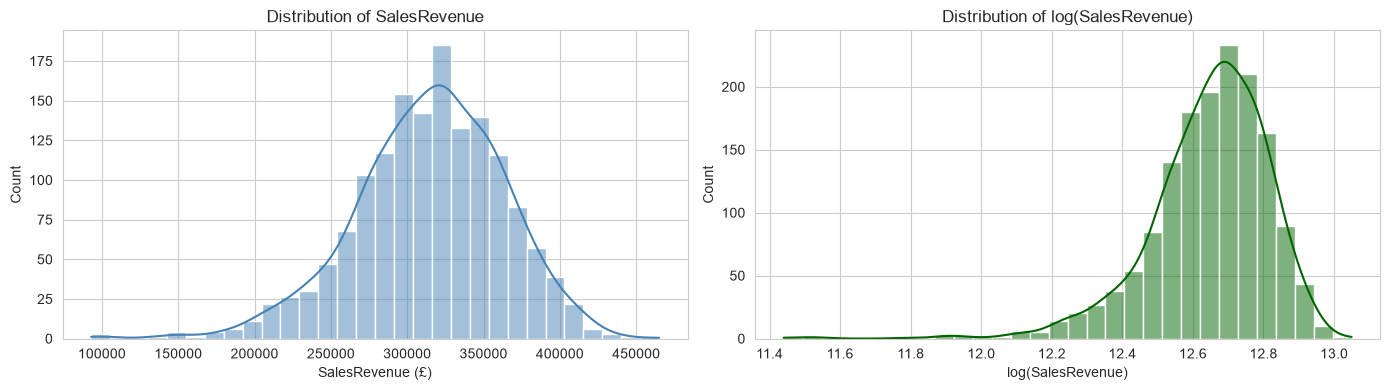

In [11]:
print("=== SUMMARY STATISTICS (key metrics) ===")
print(retail_clean[['SalesRevenue','MarketingSpend','Footfall',
                     'OnlineTraffic','CustomerSatisfaction','DiscountRate']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(retail_clean['SalesRevenue'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of SalesRevenue')
axes[0].set_xlabel('SalesRevenue (£)')

sns.histplot(np.log1p(retail_clean['SalesRevenue']), bins=30, kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title('Distribution of log(SalesRevenue)')
axes[1].set_xlabel('log(SalesRevenue)')
plt.tight_layout()
plt.show()